#Task 1: Student Performance Prediction System


  Baseline Model
  Accuracy : 0.9750
  F1-Score : 0.9780
              precision    recall  f1-score   support

        Fail       0.99      0.95      0.97        88
        Pass       0.97      0.99      0.98       112

    accuracy                           0.97       200
   macro avg       0.98      0.97      0.97       200
weighted avg       0.98      0.97      0.97       200


  Improved Model (Dropout + Early Stopping)
  Accuracy : 0.9850
  F1-Score : 0.9867
              precision    recall  f1-score   support

        Fail       0.99      0.98      0.98        88
        Pass       0.98      0.99      0.99       112

    accuracy                           0.98       200
   macro avg       0.99      0.98      0.98       200
weighted avg       0.99      0.98      0.98       200



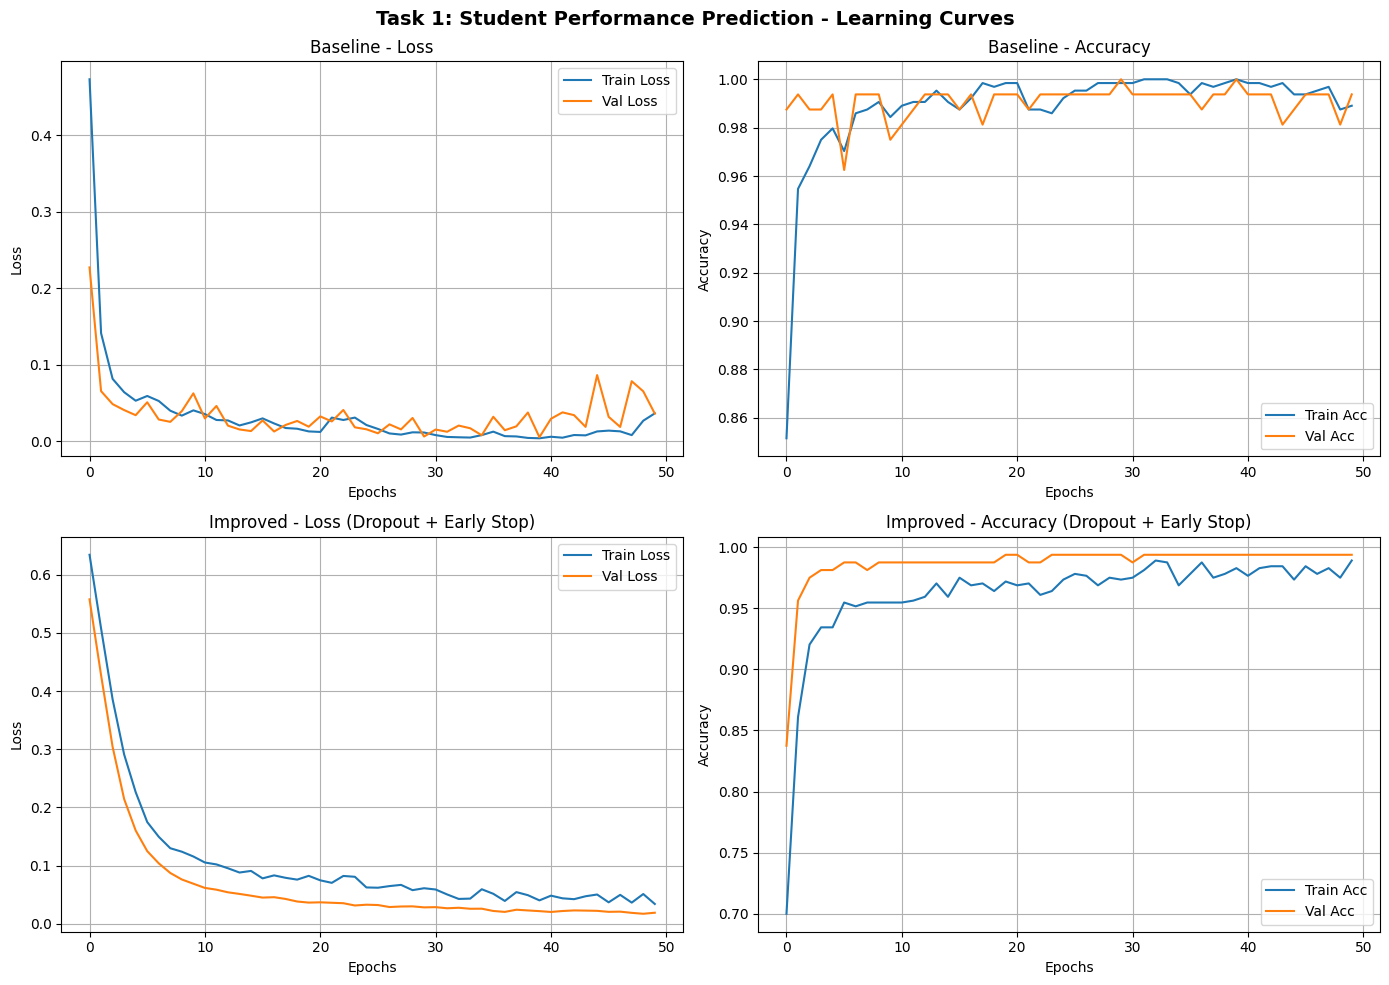

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')
from sklearn.metrics import classification_report, f1_score, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


np.random.seed(42)
n_samples = 1000

study_hours = np.random.uniform(0, 10, n_samples)
attendance = np.random.uniform(50, 100, n_samples)
assignment = np.random.uniform(40, 100, n_samples)
sleep_hours = np.random.uniform(4, 10, n_samples)

score = (study_hours * 3 + attendance * 0.2 + assignment * 0.5 + sleep_hours * 1.5)
labels = (score > np.percentile(score, 40)).astype(int)

X = np.column_stack([study_hours, attendance, assignment, sleep_hours])
y = labels

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

def build_baseline():
    return tf.keras.Sequential([
        tf.keras.layers.Dense(256, activation='relu', input_shape=(4,)),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

baseline = build_baseline()
baseline.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history_base = baseline.fit(
    X_train, y_train,
    epochs=50, batch_size=32,
    validation_split=0.2, verbose=0
)


def build_improved():
    return tf.keras.Sequential([
        tf.keras.layers.Dense(64, activation='relu', input_shape=(4,)),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

improved = build_improved()
improved.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True
)

history_impr = improved.fit(
    X_train, y_train,
    epochs=50, batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop], verbose=0
)


def evaluate(model, X_test, y_test, name):
    y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int)
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred)
    print(f"\n{'='*40}")
    print(f"  {name}")
    print(f"{'='*40}")
    print(f"  Accuracy : {acc:.4f}")
    print(f"  F1-Score : {f1:.4f}")
    print(classification_report(y_test, y_pred, target_names=["Fail", "Pass"]))
    return acc, f1

acc_b, f1_b = evaluate(baseline, X_test, y_test, "Baseline Model")
acc_i, f1_i = evaluate(improved,  X_test, y_test, "Improved Model (Dropout + Early Stopping)")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Task 1: Student Performance Prediction - Learning Curves", fontsize=14, fontweight='bold')

axes[0, 0].plot(history_base.history['loss'],     label='Train Loss')
axes[0, 0].plot(history_base.history['val_loss'], label='Val Loss')
axes[0, 0].set_title("Baseline - Loss")
axes[0, 0].set_xlabel("Epochs"); axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend(); axes[0, 0].grid(True)

axes[0, 1].plot(history_base.history['accuracy'],     label='Train Acc')
axes[0, 1].plot(history_base.history['val_accuracy'], label='Val Acc')
axes[0, 1].set_title("Baseline - Accuracy")
axes[0, 1].set_xlabel("Epochs"); axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend(); axes[0, 1].grid(True)

axes[1, 0].plot(history_impr.history['loss'],     label='Train Loss')
axes[1, 0].plot(history_impr.history['val_loss'], label='Val Loss')
axes[1, 0].set_title("Improved - Loss (Dropout + Early Stop)")
axes[1, 0].set_xlabel("Epochs"); axes[1, 0].set_ylabel("Loss")
axes[1, 0].legend(); axes[1, 0].grid(True)

axes[1, 1].plot(history_impr.history['accuracy'],     label='Train Acc')
axes[1, 1].plot(history_impr.history['val_accuracy'], label='Val Acc')
axes[1, 1].set_title("Improved - Accuracy (Dropout + Early Stop)")
axes[1, 1].set_xlabel("Epochs"); axes[1, 1].set_ylabel("Accuracy")
axes[1, 1].legend(); axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

#Task 2: Loan Default Risk Prediction

Using Colab cache for faster access to the 'loan-prediction-problem-dataset' dataset.
Dataset downloaded to: /kaggle/input/loan-prediction-problem-dataset
Files: ['test_Y3wMUE5_7gLdaTN.csv', 'train_u6lujuX_CVtuZ9i.csv']

Dataset shape : (614, 13)
Columns       : ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

First 5 rows:
    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0

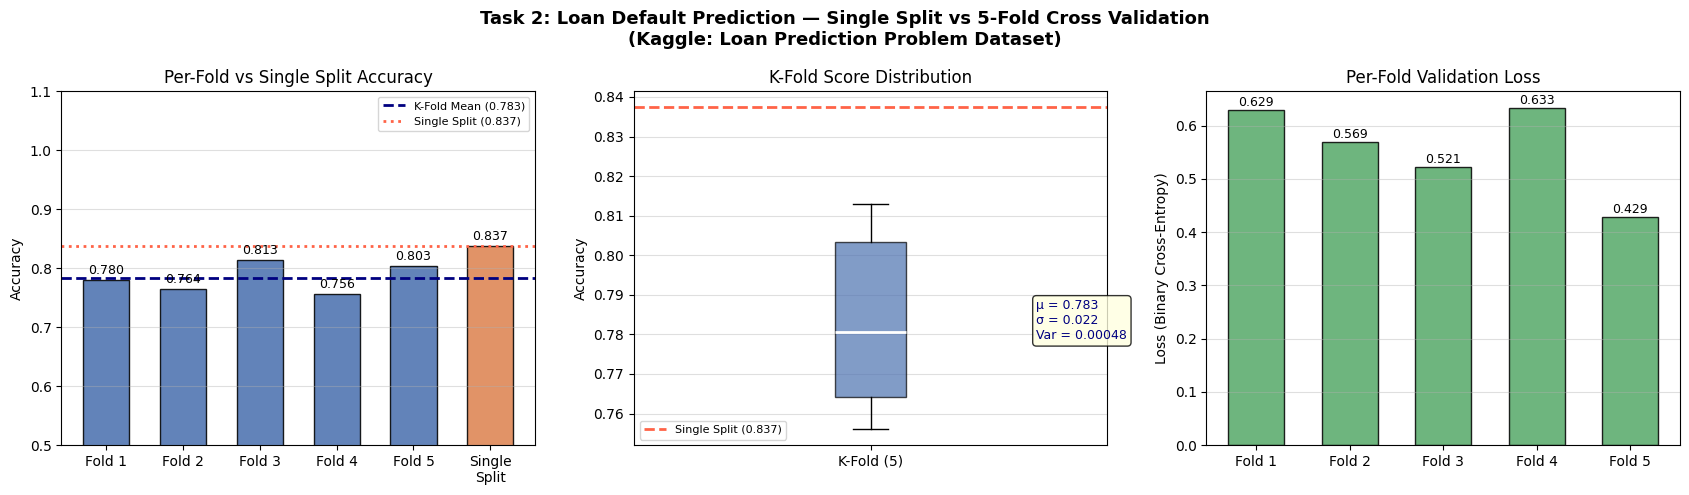

In [2]:
import kagglehub
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

path = kagglehub.dataset_download("altruistdelhite04/loan-prediction-problem-dataset")
print("Dataset downloaded to:", path)

files = os.listdir(path)
print("Files:", files)

train_file = os.path.join(path, "train_u6lujuX_CVtuZ9i.csv")
df = pd.read_csv(train_file)

print(f"\nDataset shape : {df.shape}")
print(f"Columns       : {list(df.columns)}")
print(f"\nFirst 5 rows:\n{df.head()}")
print(f"\nClass distribution:\n{df['Loan_Status'].value_counts()}")
print(f"\nMissing values:\n{df.isnull().sum()}")

#Processing of Target Variable
df.drop(columns=['Loan_ID'], inplace=True)

#Fill missing values
df['Gender'].fillna(df['Gender'].mode()[0], inplace=True)
df['Married'].fillna(df['Married'].mode()[0], inplace=True)

df['Dependents'].fillna(df['Dependents'].mode()[0], inplace=True)
df['Self_Employed'].fillna(df['Self_Employed'].mode()[0], inplace=True)

df['LoanAmount'].fillna(df['LoanAmount'].median(), inplace=True)
df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mode()[0], inplace=True)
df['Credit_History'].fillna(df['Credit_History'].mode()[0], inplace=True)

#Categorical Column Encoding
le = LabelEncoder()
cat_cols = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

#Feature Engineering
df['Total_Income']     = df['ApplicantIncome'] + df['CoapplicantIncome']
df['Income_per_month'] = df['Total_Income'] / (df['Loan_Amount_Term'] / 12 + 1e-6)
df['EMI']              = df['LoanAmount'] / (df['Loan_Amount_Term'] + 1e-6)
df['Balance_Income']   = df['Total_Income'] - (df['EMI'] * 1000)

#Target and Features
y = (df['Loan_Status'] == 'Y').astype(int).values
feature_cols = [c for c in df.columns if c != 'Loan_Status']
X = df[feature_cols].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"\nFeatures used ({len(feature_cols)}): {feature_cols}")
print(f"Positive (Approved) rate: {y.mean():.2%}")

def build_model(input_dim):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(1,  activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

X_tr, X_te, y_tr, y_te = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

simple_model = build_model(X_scaled.shape[1])
simple_model.fit(X_tr, y_tr, epochs=50, batch_size=16, verbose=0)

simple_pred = (simple_model.predict(X_te, verbose=0) > 0.5).astype(int)
simple_acc  = accuracy_score(y_te, simple_pred)

print("\n" + "="*50)
print("  SIMPLE TRAIN-TEST SPLIT (80/20)")
print("="*50)
print(f"  Accuracy: {simple_acc:.4f}")
print(classification_report(y_te, simple_pred, target_names=['Rejected', 'Approved']))

kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_accs   = []
fold_losses = []

print("\n" + "="*50)
print("  5-FOLD CROSS VALIDATION")
print("="*50)

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_scaled)):
    X_f_tr, X_f_val = X_scaled[tr_idx], X_scaled[val_idx]
    y_f_tr, y_f_val = y[tr_idx],        y[val_idx]

    model = build_model(X_scaled.shape[1])
    model.fit(X_f_tr, y_f_tr, epochs=50, batch_size=16, verbose=0)
    loss, acc = model.evaluate(X_f_val, y_f_val, verbose=0)
    fold_accs.append(acc)
    fold_losses.append(loss)
    print(f"  Fold {fold+1}  →  Accuracy: {acc:.4f}  |  Loss: {loss:.4f}")

mean_acc = np.mean(fold_accs)
std_acc  = np.std(fold_accs)
var_acc  = np.var(fold_accs)

print(f"\n  Mean Accuracy : {mean_acc:.4f}")
print(f"  Std Deviation : {std_acc:.4f}")
print(f"  Variance      : {var_acc:.6f}")
print(f"\n  Single Split  : {simple_acc:.4f}")
print(f"  Difference    : {abs(mean_acc - simple_acc):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle(
    "Task 2: Loan Default Prediction — Single Split vs 5-Fold Cross Validation\n"
    "(Kaggle: Loan Prediction Problem Dataset)",
    fontsize=13, fontweight='bold'
)

fold_labels = [f"Fold {i+1}" for i in range(5)] + ["Single\nSplit"]
all_scores  = fold_accs + [simple_acc]
bar_colors  = ['#4C72B0'] * 5 + ['#DD8452']

bars = axes[0].bar(fold_labels, all_scores, color=bar_colors,
                   edgecolor='black', alpha=0.88, width=0.6)
axes[0].axhline(mean_acc,   color='navy',  ls='--', lw=2, label=f'K-Fold Mean ({mean_acc:.3f})')
axes[0].axhline(simple_acc, color='tomato', ls=':',  lw=2, label=f'Single Split ({simple_acc:.3f})')
for bar, val in zip(bars, all_scores):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.005,
                 f'{val:.3f}', ha='center', va='bottom', fontsize=9)
axes[0].set_ylim(0.5, 1.1)
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Per-Fold vs Single Split Accuracy")
axes[0].legend(fontsize=8)
axes[0].grid(axis='y', alpha=0.4)

axes[1].boxplot(fold_accs, vert=True, patch_artist=True,
                boxprops=dict(facecolor='#4C72B0', alpha=0.7),
                medianprops=dict(color='white', linewidth=2))
axes[1].axhline(simple_acc, color='tomato', ls='--', lw=2, label=f'Single Split ({simple_acc:.3f})')
axes[1].set_xticks([1])
axes[1].set_xticklabels(['K-Fold (5)'])
axes[1].set_ylabel("Accuracy")
axes[1].set_title("K-Fold Score Distribution")
axes[1].legend(fontsize=8)
axes[1].grid(axis='y', alpha=0.4)
axes[1].text(1.35, mean_acc,
             f'μ = {mean_acc:.3f}\nσ = {std_acc:.3f}\nVar = {var_acc:.5f}',
             fontsize=9, va='center', color='navy',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

axes[2].bar([f"Fold {i+1}" for i in range(5)], fold_losses,
            color='#55A868', edgecolor='black', alpha=0.85, width=0.6)
for i, v in enumerate(fold_losses):
    axes[2].text(i, v + 0.002, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
axes[2].set_ylabel("Loss (Binary Cross-Entropy)")
axes[2].set_title("Per-Fold Validation Loss")
axes[2].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig("task2_kfold_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

#Task 3: Medical Diagnosis (Diabetes Prediction)

Loaded Pima Indians Diabetes Dataset successfully.

  Deep Baseline Model (Overfitting)
              precision    recall  f1-score   support

 No Diabetes       0.78      0.73      0.75        99
    Diabetes       0.56      0.64      0.60        55

    accuracy                           0.69       154
   macro avg       0.67      0.68      0.68       154
weighted avg       0.70      0.69      0.70       154


  Regularized Model (Dropout + Early Stop)
              precision    recall  f1-score   support

 No Diabetes       0.80      0.82      0.81        99
    Diabetes       0.66      0.64      0.65        55

    accuracy                           0.75       154
   macro avg       0.73      0.73      0.73       154
weighted avg       0.75      0.75      0.75       154



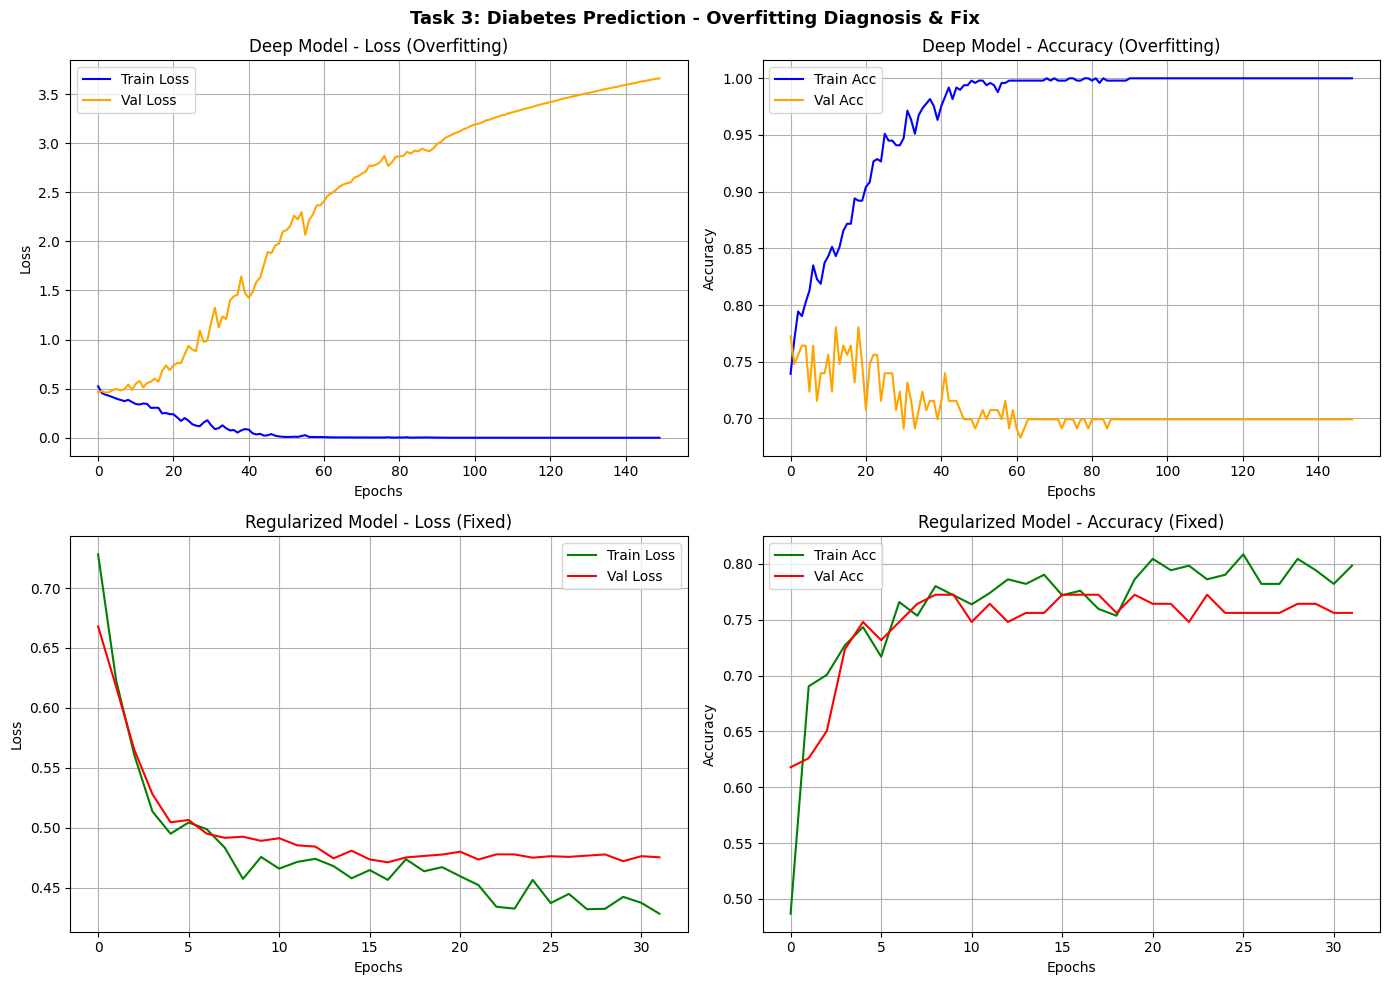

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix


url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
        'Insulin','BMI','DiabetesPedigree','Age','Outcome']
df = pd.read_csv(url, names=cols)
X = df.drop('Outcome', axis=1).values
y = df['Outcome'].values
print("Loaded Pima Indians Diabetes Dataset successfully.")

scaler = StandardScaler()
X = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def build_deep_model():
    return tf.keras.Sequential([
        tf.keras.layers.Dense(512, activation='relu', input_shape=(X.shape[1],)),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(64,  activation='relu'),
        tf.keras.layers.Dense(1,   activation='sigmoid')
    ])

def build_regularized_model():
    return tf.keras.Sequential([
        tf.keras.layers.Dense(64, activation='relu', input_shape=(X.shape[1],)),
        tf.keras.layers.Dropout(0.4),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(1,  activation='sigmoid')
    ])

deep_model = build_deep_model()
deep_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history_deep = deep_model.fit(
    X_train, y_train, epochs=150, batch_size=16,
    validation_split=0.2, verbose=0
)

reg_model = build_regularized_model()
reg_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=15, restore_best_weights=True
)
history_reg = reg_model.fit(
    X_train, y_train, epochs=200, batch_size=16,
    validation_split=0.2, callbacks=[early_stop], verbose=0
)

def evaluate(model, name):
    y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int)
    print(f"\n{'='*45}")
    print(f"  {name}")
    print(f"{'='*45}")
    print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))

evaluate(deep_model, "Deep Baseline Model (Overfitting)")
evaluate(reg_model,  "Regularized Model (Dropout + Early Stop)")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Task 3: Diabetes Prediction - Overfitting Diagnosis & Fix", fontsize=13, fontweight='bold')

axes[0, 0].plot(history_deep.history['loss'],     label='Train Loss', color='blue')
axes[0, 0].plot(history_deep.history['val_loss'], label='Val Loss',   color='orange')
axes[0, 0].set_title("Deep Model - Loss (Overfitting)")
axes[0, 0].set_xlabel("Epochs"); axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend(); axes[0, 0].grid(True)

axes[0, 1].plot(history_deep.history['accuracy'],     label='Train Acc', color='blue')
axes[0, 1].plot(history_deep.history['val_accuracy'], label='Val Acc',   color='orange')
axes[0, 1].set_title("Deep Model - Accuracy (Overfitting)")
axes[0, 1].set_xlabel("Epochs"); axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend(); axes[0, 1].grid(True)

axes[1, 0].plot(history_reg.history['loss'],     label='Train Loss', color='green')
axes[1, 0].plot(history_reg.history['val_loss'], label='Val Loss',   color='red')
axes[1, 0].set_title("Regularized Model - Loss (Fixed)")
axes[1, 0].set_xlabel("Epochs"); axes[1, 0].set_ylabel("Loss")
axes[1, 0].legend(); axes[1, 0].grid(True)

axes[1, 1].plot(history_reg.history['accuracy'],     label='Train Acc', color='green')
axes[1, 1].plot(history_reg.history['val_accuracy'], label='Val Acc',   color='red')
axes[1, 1].set_title("Regularized Model - Accuracy (Fixed)")
axes[1, 1].set_xlabel("Epochs"); axes[1, 1].set_ylabel("Accuracy")
axes[1, 1].legend(); axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

#Task 4: Image Classification - Fashion Items

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train: (60000, 784), Test: (10000, 784)

Training Baseline ANN...
Training Improved ANN (Dropout + Early Stopping)...

Baseline  → Test Accuracy: 0.8940  |  Test Loss: 0.4195
Improved  → Test Accuracy: 0.8850  |  Test Loss: 0.3220


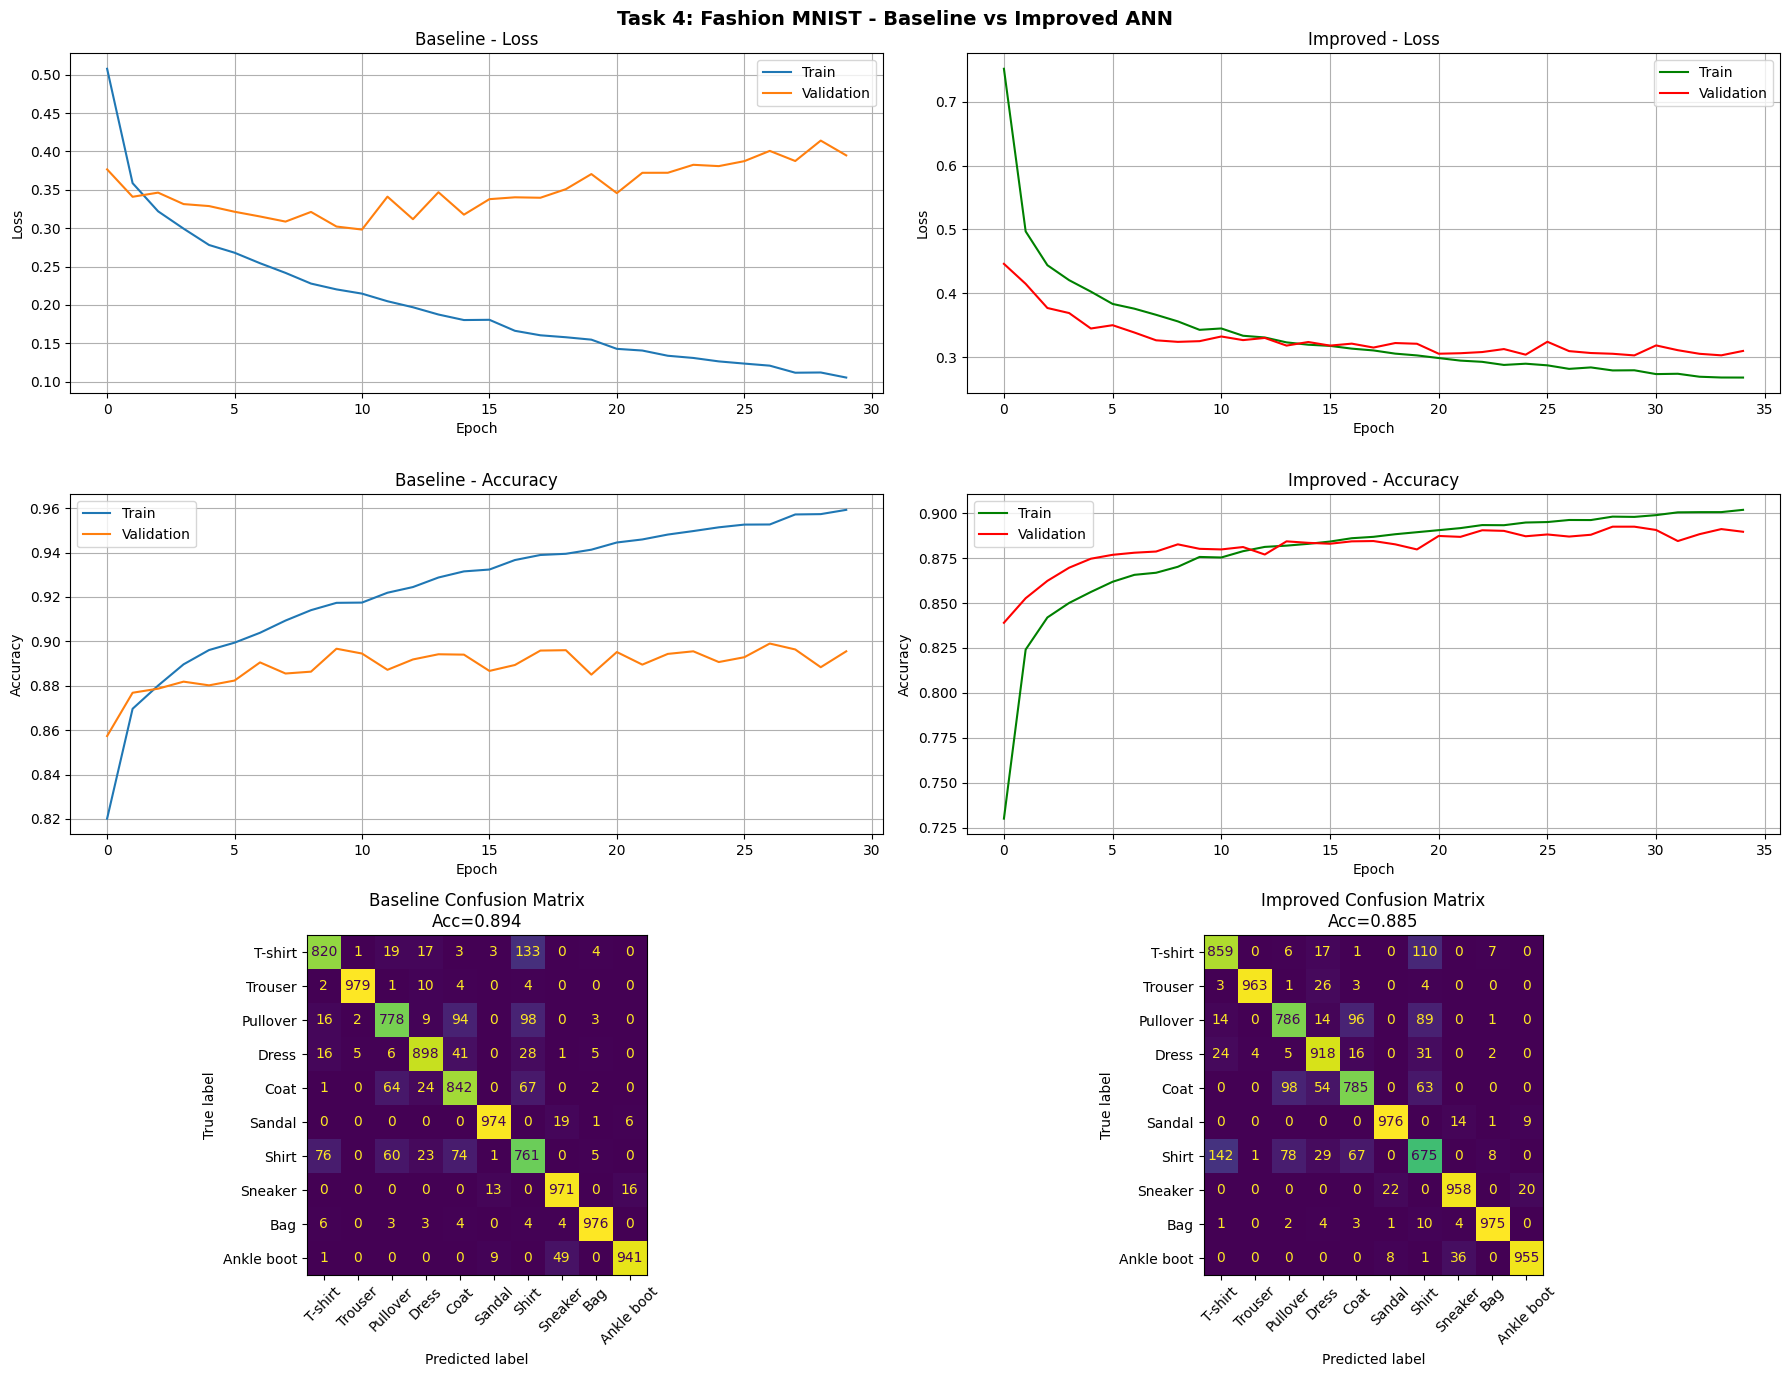

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

#Normalize pixel values to [0, 1]
X_train = X_train / 255.0
X_test  = X_test  / 255.0

#Flatten 28x28 images to 784 for ANN
X_train_flat = X_train.reshape(-1, 784)
X_test_flat  = X_test.reshape(-1, 784)

class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print(f"Train: {X_train_flat.shape}, Test: {X_test_flat.shape}")

def build_baseline():
    return tf.keras.Sequential([
        tf.keras.layers.Dense(512, activation='relu', input_shape=(784,)),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(10,  activation='softmax')
    ])

def build_improved():
    return tf.keras.Sequential([
        tf.keras.layers.Dense(256, activation='relu', input_shape=(784,)),
        tf.keras.layers.Dropout(0.4),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64,  activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(10,  activation='softmax')
    ])

#Train baseline
print("\nTraining Baseline ANN...")
baseline = build_baseline()
baseline.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_base = baseline.fit(
    X_train_flat, y_train,
    epochs=30, batch_size=128,
    validation_split=0.1, verbose=0
)

#Train improved
print("Training Improved ANN (Dropout + Early Stopping)...")
improved = build_improved()
improved.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)
history_impr = improved.fit(
    X_train_flat, y_train,
    epochs=50, batch_size=128,
    validation_split=0.1,
    callbacks=[early_stop], verbose=0
)

base_loss, base_acc = baseline.evaluate(X_test_flat, y_test, verbose=0)
impr_loss, impr_acc = improved.evaluate(X_test_flat, y_test, verbose=0)

print(f"\nBaseline  → Test Accuracy: {base_acc:.4f}  |  Test Loss: {base_loss:.4f}")
print(f"Improved  → Test Accuracy: {impr_acc:.4f}  |  Test Loss: {impr_loss:.4f}")

#Predictions for confusion matrix
y_pred_base = np.argmax(baseline.predict(X_test_flat, verbose=0), axis=1)
y_pred_impr = np.argmax(improved.predict(X_test_flat, verbose=0), axis=1)

fig = plt.figure(figsize=(18, 14))
fig.suptitle("Task 4: Fashion MNIST - Baseline vs Improved ANN", fontsize=14, fontweight='bold')

#Row 1: Loss curves
ax1 = fig.add_subplot(3, 2, 1)
ax1.plot(history_base.history['loss'],     label='Train')
ax1.plot(history_base.history['val_loss'], label='Validation')
ax1.set_title("Baseline - Loss"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
ax1.legend(); ax1.grid(True)

ax2 = fig.add_subplot(3, 2, 2)
ax2.plot(history_impr.history['loss'],     label='Train',      color='green')
ax2.plot(history_impr.history['val_loss'], label='Validation', color='red')
ax2.set_title("Improved - Loss"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Loss")
ax2.legend(); ax2.grid(True)

#Row 2: Accuracy curves
ax3 = fig.add_subplot(3, 2, 3)
ax3.plot(history_base.history['accuracy'],     label='Train')
ax3.plot(history_base.history['val_accuracy'], label='Validation')
ax3.set_title("Baseline - Accuracy"); ax3.set_xlabel("Epoch"); ax3.set_ylabel("Accuracy")
ax3.legend(); ax3.grid(True)

ax4 = fig.add_subplot(3, 2, 4)
ax4.plot(history_impr.history['accuracy'],     label='Train',      color='green')
ax4.plot(history_impr.history['val_accuracy'], label='Validation', color='red')
ax4.set_title("Improved - Accuracy"); ax4.set_xlabel("Epoch"); ax4.set_ylabel("Accuracy")
ax4.legend(); ax4.grid(True)

#Row 3: Confusion Matrices
ax5 = fig.add_subplot(3, 2, 5)
cm_base = confusion_matrix(y_test, y_pred_base)
disp = ConfusionMatrixDisplay(cm_base, display_labels=class_names)
disp.plot(ax=ax5, colorbar=False, xticks_rotation=45)
ax5.set_title(f"Baseline Confusion Matrix\nAcc={base_acc:.3f}")

ax6 = fig.add_subplot(3, 2, 6)
cm_impr = confusion_matrix(y_test, y_pred_impr)
disp2 = ConfusionMatrixDisplay(cm_impr, display_labels=class_names)
disp2.plot(ax=ax6, colorbar=False, xticks_rotation=45)
ax6.set_title(f"Improved Confusion Matrix\nAcc={impr_acc:.3f}")

plt.tight_layout()
plt.show()